# 85 · From CNN to ViT: patches as tokens, and what a pretrained ViT attends to in TableTop

In [1]:
import numpy as np, torch, torch.nn as nn, torchvision, matplotlib.pyplot as plt
from transformers import AutoModel, AutoImageProcessor
from vlacourse import TableTop, show_images

class PatchEmbed(nn.Module):
    def __init__(self, img=224, patch=16, d=384):
        super().__init__()
        self.proj = nn.Conv2d(3, d, patch, stride=patch)
        self.n = (img // patch) ** 2
    def forward(self, x):
        return self.proj(x).flatten(2).transpose(1, 2)

class TinyViT(nn.Module):
    def __init__(self, img=224, patch=16, d=384, depth=6, heads=6, n_cls=10):
        super().__init__()
        self.patch = PatchEmbed(img, patch, d)
        self.cls = nn.Parameter(torch.zeros(1, 1, d)); self.pos = nn.Parameter(torch.randn(1, self.patch.n + 1, d) * 0.02)
        self.blocks = nn.TransformerEncoder(nn.TransformerEncoderLayer(d, heads, 4 * d, 0.0, batch_first=True, norm_first=True), depth)
        self.head = nn.Linear(d, n_cls)
    def forward(self, x):
        t = torch.cat([self.cls.expand(x.shape[0], -1, -1), self.patch(x)], 1) + self.pos
        return self.head(self.blocks(t)[:, 0])

def patch_grid(img, p=16):
    h, w = img.shape[:2]
    out = img.copy()
    out[::p] = 255; out[:, ::p] = 255
    return out

~/anaconda3/envs/vla/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


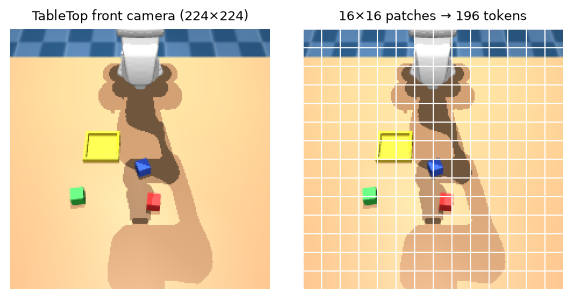

In [2]:
env = TableTop(cameras=("front",), image_size=(224, 224), seed=0)
img = env.reset(seed=3)["images"]["front"]
show_images([img, patch_grid(img)], ["TableTop front camera (224×224)", "16×16 patches → 196 tokens"])

In [3]:
vit, cnn = TinyViT(), torchvision.models.resnet18()
x = torch.rand(2, 3, 224, 224)
print("patch tokens:", vit.patch(x).shape, "-> + CLS =", vit.patch.n + 1, "tokens of width 384")
print(f"TinyViT params {sum(p.numel() for p in vit.parameters()) / 1e6:.1f}M | ResNet-18 params {sum(p.numel() for p in cnn.parameters()) / 1e6:.1f}M")
print("ViT inductive bias: none besides patching (no locality, no translation equivariance) -> needs more data or pretraining")

patch tokens: torch.Size([2, 196, 384]) -> + CLS = 197 tokens of width 384
TinyViT params 11.0M | ResNet-18 params 11.7M
ViT inductive bias: none besides patching (no locality, no translation equivariance) -> needs more data or pretraining


/tmp/ipykernel_1120239/111257816.py:18: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.blocks = nn.TransformerEncoder(nn.TransformerEncoderLayer(d, heads, 4 * d, 0.0, batch_first=True, norm_first=True), depth)


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 223/223 [00:00<00:00, 23366.30it/s]


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.009054691..1.1600001].


DINOv2-S input (1, 3, 224, 224) | tokens per image 257 | heads 6


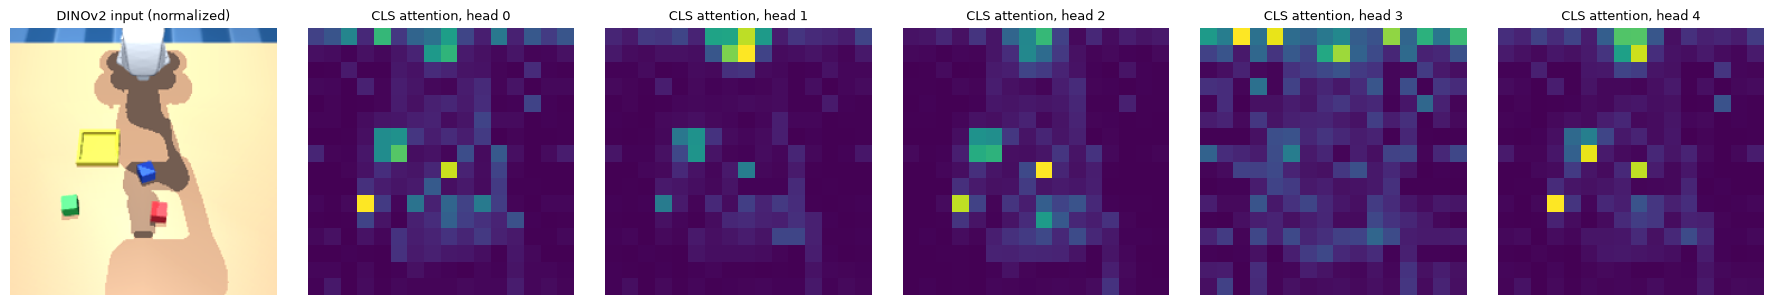

Without any labels, heads attend to the robot, the cubes and the tray: self-supervised features are object-centric.


In [4]:
proc = AutoImageProcessor.from_pretrained("facebook/dinov2-small")
dino = AutoModel.from_pretrained("facebook/dinov2-small", attn_implementation="eager").eval()
inputs = proc(images=img, return_tensors="pt")
with torch.no_grad():
    out = dino(**inputs, output_attentions=True)
att = out.attentions[-1][0, :, 0, 1:]
n = int(att.shape[-1] ** 0.5)
maps = att.reshape(-1, n, n)
print("DINOv2-S input", tuple(inputs["pixel_values"].shape), "| tokens per image", out.last_hidden_state.shape[1], "| heads", maps.shape[0])
show_images([inputs["pixel_values"][0].permute(1, 2, 0).numpy() * 0.25 + 0.5] + [m.numpy() for m in maps[:5]],
            ["DINOv2 input (normalized)"] + [f"CLS attention, head {h}" for h in range(5)], cols=6)
print("Without any labels, heads attend to the robot, the cubes and the tray: self-supervised features are object-centric.")